# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

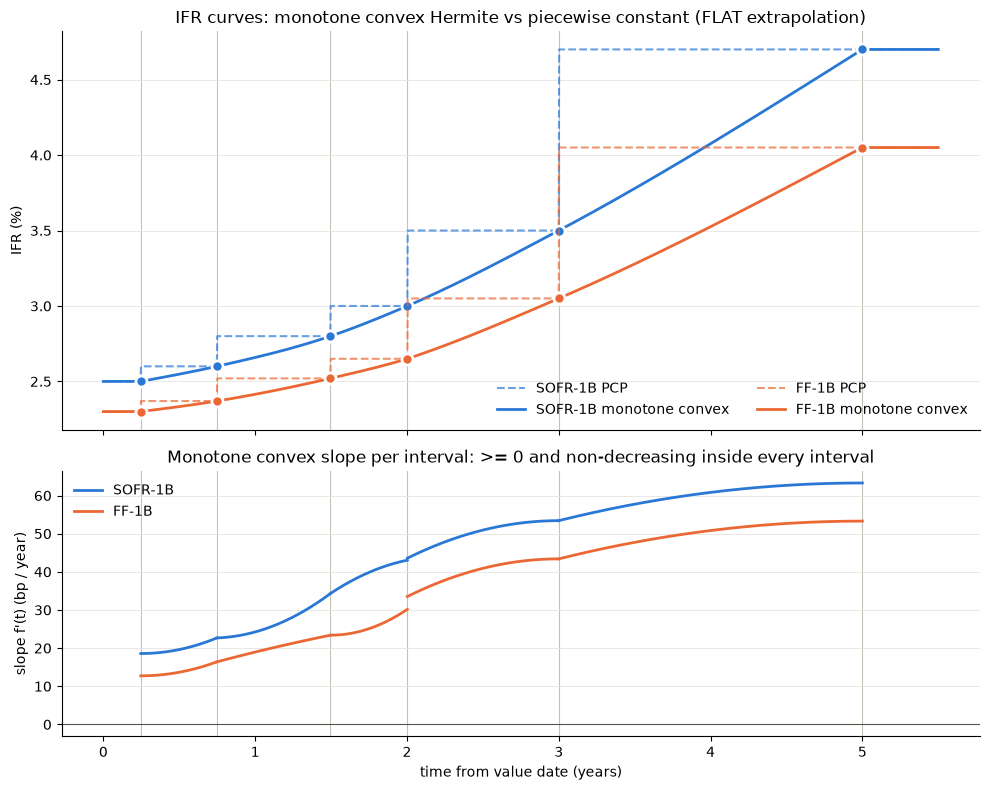

SOFR-1B: monotone per interval = True, convex per interval = True, slope kinks at interior nodes (bp/yr) = [0.    0.    0.515 0.   ]
FF-1B: monotone per interval = True, convex per interval = True, slope kinks at interior nodes (bp/yr) = [0.    0.    3.359 0.   ]
Funding curve (one node) is constant: True


In [2]:
import numpy as np
import matplotlib.pyplot as plt

def build_curve_model(interp_method):
    methods = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {**inputs,
                                   "INTERPOLATION METHOD": interp_method,
                                   "EXTRAPOLATION METHOD": "FLAT"})
        for kind, inputs in curve_inputs
    ])
    return qfCreateModel("2026-01-02", "YIELD_CURVE", data_collection, methods)

models = {m: build_curve_model(m) for m in ["PIECEWISE_CONSTANT_LEFT_CONTINUOUS", "MONOTONE_CONVEX"]}
curves = {"SOFR-1B": "#2a78d6", "FF-1B": "#eb6834"}   # colour = curve, line style = method
grid = np.linspace(0.0, 5.5, 2201)

fig, (ax_f, ax_d) = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 2]})
for name, colour in curves.items():
    mc = models["MONOTONE_CONVEX"].retrieve_model_component(name).state_data_interpolator
    pcp = models["PIECEWISE_CONSTANT_LEFT_CONTINUOUS"].retrieve_model_component(name).state_data_interpolator
    t_nodes, f_nodes = np.asarray(mc.axis1, float), np.asarray(mc.values, float)

    f_mc = np.array([mc.interpolate(x) for x in grid])
    f_pcp = np.array([pcp.interpolate(x) for x in grid])
    ax_f.plot(grid, f_pcp * 100, color=colour, lw=1.5, ls="--", alpha=0.7, label=f"{name} PCP")
    ax_f.plot(grid, f_mc * 100, color=colour, lw=2, label=f"{name} monotone convex")
    ax_f.plot(t_nodes, f_nodes * 100, "o", ms=8, color=colour, mec="white", mew=2)

    # Slope f'(t) per interval: must keep one sign (monotone) and be non-decreasing (convex).
    for i in range(len(t_nodes) - 1):
        x = np.linspace(t_nodes[i], t_nodes[i + 1], 200)
        tau = x - t_nodes[i]
        slope = mc.dL_[i] + 2 * mc.c2_[i] * tau + 3 * mc.c3_[i] * tau**2
        ax_d.plot(x, slope * 1e4, color=colour, lw=2, label=name if i == 0 else None)

for t in models["MONOTONE_CONVEX"].retrieve_model_component("SOFR-1B").state_data_interpolator.axis1:
    for ax in (ax_f, ax_d):
        ax.axvline(t, color="#c3c2b7", lw=0.8, zorder=0)

ax_f.set_ylabel("IFR (%)")
ax_f.set_title("IFR curves: monotone convex Hermite vs piecewise constant (FLAT extrapolation)")
ax_f.legend(frameon=False, ncol=2)
ax_d.axhline(0, color="#52514e", lw=0.8)
ax_d.set_ylabel("slope f'(t) (bp / year)")
ax_d.set_xlabel("time from value date (years)")
ax_d.set_title("Monotone convex slope per interval: >= 0 and non-decreasing inside every interval")
ax_d.legend(frameon=False)
for ax in (ax_f, ax_d):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", lw=0.6)
plt.tight_layout()
plt.show()

# Numerical shape check on a fine grid inside each interval.
for name in curves:
    mc = models["MONOTONE_CONVEX"].retrieve_model_component(name).state_data_interpolator
    t_nodes = np.asarray(mc.axis1, float)
    mono = conv = True
    for i in range(len(t_nodes) - 1):
        y = np.array([mc.interpolate(x) for x in np.linspace(t_nodes[i], t_nodes[i + 1], 401)])
        mono &= bool(np.all(np.diff(y) >= -1e-14) or np.all(np.diff(y) <= 1e-14))
        conv &= bool(np.all(np.diff(y, 2) >= -1e-13))
    kinks = (mc.dL_[1:] - mc.dR_[:-1]) * 1e4
    print(f"{name}: monotone per interval = {mono}, convex per interval = {conv}, "
          f"slope kinks at interior nodes (bp/yr) = {np.round(kinks, 3)}")
funding = models["MONOTONE_CONVEX"].retrieve_model_component("SOFR-1B-FLAT").state_data_interpolator
print("Funding curve (one node) is constant:",
      all(funding.interpolate(x) == 0.0005 for x in [0.0, 1.0, 3.0, 10.0]))

**How the method works.** On each node interval the IFR is a cubic Hermite polynomial. It is fixed by the two node values and by the slopes at the two ends, $d^L$ and $d^R$. Write $\Delta$ for the secant slope and measure the end slopes against it: $a=\Delta-d^L$ and $b=d^R-\Delta$. Then

$$p(\tau)=f_i+d^L\tau+\frac{2a-b}{h}\tau^2+\frac{b-a}{h^2}\tau^3 .$$

- **Interpolation and continuity.** Each piece passes through both of its nodes, so the curve is continuous. FLAT extrapolation continues the first and last node values, so it is continuous too. The one-node funding curve is constant.
- **Convexity.** $p''$ is linear in $\tau$, so it is $\ge 0$ on the whole interval exactly when it is $\ge 0$ at both ends. That reduces to $a,b\ge 0$ and $\tfrac12 a\le b\le 2a$: the slope undershoot on the left and the overshoot on the right must be within a factor of 2 of each other.
- **Monotonicity.** On a convex piece $p'$ only increases, so one end is enough to check: $d^L\ge 0$ when the interval is increasing (that is, $a\le\Delta$), or $d^R\le 0$ when it is decreasing.
- **Choosing the slopes.** Start from shared node slopes: the Bessel three-point slope in the interior, $0$ at a local extremum, and the natural condition $p''=0$ at the end nodes. Then each interval projects its own $(a,b)$ into the feasible region by clipping negative values to 0, enforcing the factor-2 band, and capping for monotonicity. The point $(0,0)$, which is linear interpolation, is always feasible, so this always succeeds.

**Data that cannot satisfy everything.** The priorities are interpolation, then continuity, then monotonicity and convexity on each interval, and only after that a continuous slope ($C^1$). If the slopes a node's two neighbouring intervals need conflict, for example concave data or two strongly different curvatures, the node gets a slope kink and the interval tends toward linear. A local extremum gets a zero slope, so there is no overshoot. Because every piece is monotone, the forwards always stay between neighbouring node values, so positive inputs give positive forwards.

On the supplied data both curves have positive, increasing secants, so the data is compatible. The only adjustment is a small kink at the 2028-01-03 node (about 0.5 bp/yr on SOFR and 3.4 bp/yr on FF; see the slope panel). Every other node keeps a continuous slope.

**Compared with PCP.** The left-continuous piecewise-constant curve (PCP) uses the *next* node's value over the whole interval. On an increasing curve that is the interval's maximum, so PCP forwards sit at or above the monotone convex curve everywhere.

In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3259.384340384593
Student minus PCP: 351.09770114662933


In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513069528


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12852.810840711812
Student minus PCP: 6630.293327642285


In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7613.817663473608
Student minus PCP: -737.5312447083852


### PV comparison

| Product | PCP PV | Monotone convex PV | Difference |
|---|---:|---:|---:|
| FRA, May–Nov 2026 (receive fixed 3.2%) | 2,908.29 | 3,259.38 | +351.10 |
| RFR swap, Apr 2026–Apr 2029 (receive fixed 3.4%) | 6,222.52 | 12,852.81 | +6,630.29 |
| Basis swap, Jul 2026–Jul 2028 (receive SOFR + 10 bp, pay FF) | 8,351.35 | 7,613.82 | −737.53 |

**Why they differ.** Both IFR curves increase. The left-continuous PCP curve applies the *next* node's value across each whole interval, which is the interval's maximum. The monotone convex curve rises gradually between the node values, so its forwards are lower almost everywhere. The plot shows the gap: zero at each node, widest just after a node, and growing with the size of the jump between nodes. The funding curve references SOFR-1B, so discount factors change too, but that is a second-order effect next to the change in projected floating payments.

- **FRA.** The accrual period (about 0.34–0.84 years) sits on the flat, closely spaced short end, where node values differ by only 10–20 bp. The forward over the period comes out a few bp lower, and the receive-fixed FRA gains about 351.
- **RFR swap.** This is the largest effect. The swap runs to April 2029, through the steep part of the curve. On (2Y, 3Y] PCP uses 3.5% while the monotone convex curve runs from 3.0% to 3.5%. On the final stub past 3Y, PCP already jumps to the 5Y node value of 4.7%, while the monotone convex curve is still near 3.5%. The floating leg is much smaller, so the receive-fixed swap gains about 6,630.
- **Basis swap.** Both legs fall, but by different amounts. SOFR's node values rise faster than FF's (for example, +50 bp vs +40 bp from 2Y to 3Y), so moving from step values to the gradual curve takes more off the SOFR forwards than off FF. The basis we receive narrows, and the swap loses about 738.

In short, PCP is biased upward on an increasing curve, and the size of that bias depends on how steep the curve is over each product's dates. A continuous interpolator removes the bias and makes PVs depend smoothly on the dates, with no jumps when a date crosses a node.